In [1]:
# ==========================================
# 1. Import Libraries
# ==========================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import joblib
import shap

print("Libraries imported successfully!")


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.2.6 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "C:\Users\vedul\AppData\Roaming\Python\Python312\site-packages\ipykernel_launcher.py", line 18, in <module>
    app.launch_new_instance()
  File "C:\Users\vedul\AppData\Roaming\Python\Python312\site-packages\traitlets\config\application.py", line 1075, in launch_instance
    app.start()
  File "C:\Users\vedul\AppData\Roaming\Python\Python312\site-packages\ipykernel\kernelapp.py", line 739, in start
    self.io_lo

ImportError: 
A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.2.6 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.



Libraries imported successfully!


In [2]:
# ==========================================
# 2. Load Saved Model & Objects
# ==========================================

rf_model = joblib.load("../models/random_forest_model.pkl")

tfidf = joblib.load("../models/tfidf_vectorizer.pkl")

feature_columns = joblib.load("../models/feature_columns.pkl")

print("Random Forest loaded successfully!")
print("TF-IDF Vectorizer loaded successfully!")
print("Feature columns loaded successfully!")

print(f"\nTotal Features: {len(feature_columns)}")

Random Forest loaded successfully!
TF-IDF Vectorizer loaded successfully!
Feature columns loaded successfully!

Total Features: 2030


In [3]:
# ==========================================
# 3. Load Dataset
# ==========================================

model_df = pd.read_csv(
    "../dataset/processed/model_dataset.csv"
)

print(model_df.shape)

model_df.head()

(5321, 19)


,budget,id,original_language,overview,revenue,runtime,profit,roi,franchise,release_year,release_month,release_quarter,release_season,genre_list,director,keyword_list,company_list,language_list,country_list
0,30000000,862,en,"Led by Woody, Andy's toys live happily in his ...",373554033.0,81.0,343554033.0,11.451801,1,1995,10,4,Fall,"['Animation', 'Comedy', 'Family']",John Lasseter,"['jealousy', 'toy', 'boy', 'friendship', 'frie...",['Pixar Animation Studios'],['English'],['United States of America']
1,65000000,8844,en,When siblings Judy and Peter discover an encha...,262797249.0,104.0,197797249.0,3.043035,0,1995,12,4,Winter,"['Adventure', 'Fantasy', 'Family']",Joe Johnston,"['board game', 'disappearance', ""based on chil...","['TriStar Pictures', 'Teitler Film', 'Intersco...","['English', 'Français']",['United States of America']
2,16000000,31357,en,"Cheated on, mistreated and stepped on, the wom...",81452156.0,127.0,65452156.0,4.090760,0,1995,12,4,Winter,"['Comedy', 'Drama', 'Romance']",Forest Whitaker,"['based on novel', 'interracial relationship',...",['Twentieth Century Fox Film Corporation'],['English'],['United States of America']
3,60000000,949,en,"Obsessive master thief, Neil McCauley leads a ...",187436818.0,170.0,127436818.0,2.123947,0,1995,12,4,Winter,"['Action', 'Crime', 'Drama', 'Thriller']",Michael Mann,"['robbery', 'detective', 'bank', 'obsession', ...","['Regency Enterprises', 'Forward Pass', 'Warne...","['English', 'Español']",['United States of America']
4,35000000,9091,en,International action superstar Jean Claude Van...,64350171.0,106.0,29350171.0,0.838576,0,1995,12,4,Winter,"['Action', 'Adventure', 'Thriller']",Peter Hyams,"['terrorist', 'hostage', 'explosive', 'vice pr...","['Universal Pictures', 'Imperial Entertainment...",['English'],['United States of America']


In [4]:
# ==========================================
# 4. Load Final Feature Matrix
# ==========================================

X_final = pd.read_csv(
    "../dataset/processed/X_final.csv"
)

print("Final Feature Matrix Shape:")
print(X_final.shape)

X_final.head()

Final Feature Matrix Shape:
(5321, 2030)


,budget,runtime,franchise,release_year,release_month,original_language_bm,original_language_ca,original_language_cn,original_language_da,original_language_de,...,worse,worst,writer,written,wrong,year,years,york,young,younger
0,30000000,81.0,1,1995,10,False,False,False,False,False,...,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0
1,65000000,104.0,0,1995,12,False,False,False,False,False,...,0.0,0.0,0.0,0.0,0.0,0.0,0.142549,0.0,0.0,0.0
2,16000000,127.0,0,1995,12,False,False,False,False,False,...,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0
3,60000000,170.0,0,1995,12,False,False,False,False,False,...,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0
4,35000000,106.0,0,1995,12,False,False,False,False,False,...,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0


In [5]:
# ==========================================
# 4. Load Final Feature Matrix
# ==========================================

X_final = pd.read_csv(
    "../dataset/processed/X_final.csv"
)

print("Final Feature Matrix Shape:")
print(X_final.shape)

X_final.head()

Final Feature Matrix Shape:
(5321, 2030)


,budget,runtime,franchise,release_year,release_month,original_language_bm,original_language_ca,original_language_cn,original_language_da,original_language_de,...,worse,worst,writer,written,wrong,year,years,york,young,younger
0,30000000,81.0,1,1995,10,False,False,False,False,False,...,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0
1,65000000,104.0,0,1995,12,False,False,False,False,False,...,0.0,0.0,0.0,0.0,0.0,0.0,0.142549,0.0,0.0,0.0
2,16000000,127.0,0,1995,12,False,False,False,False,False,...,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0
3,60000000,170.0,0,1995,12,False,False,False,False,False,...,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0
4,35000000,106.0,0,1995,12,False,False,False,False,False,...,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0


In [6]:
# ==========================================
# 5. Initialize SHAP Explainer
# ==========================================

explainer = shap.TreeExplainer(rf_model)

print("SHAP TreeExplainer created successfully!")

SHAP TreeExplainer created successfully!


In [7]:
# ==========================================
# 6. Calculate SHAP Values
# ==========================================

X_sample = X_final.sample(
    n=500,
    random_state=42
)

shap_values = explainer.shap_values(X_sample)

print("SHAP values calculated successfully!")
print("Sample Shape:", X_sample.shape)

SHAP values calculated successfully!
Sample Shape: (500, 2030)


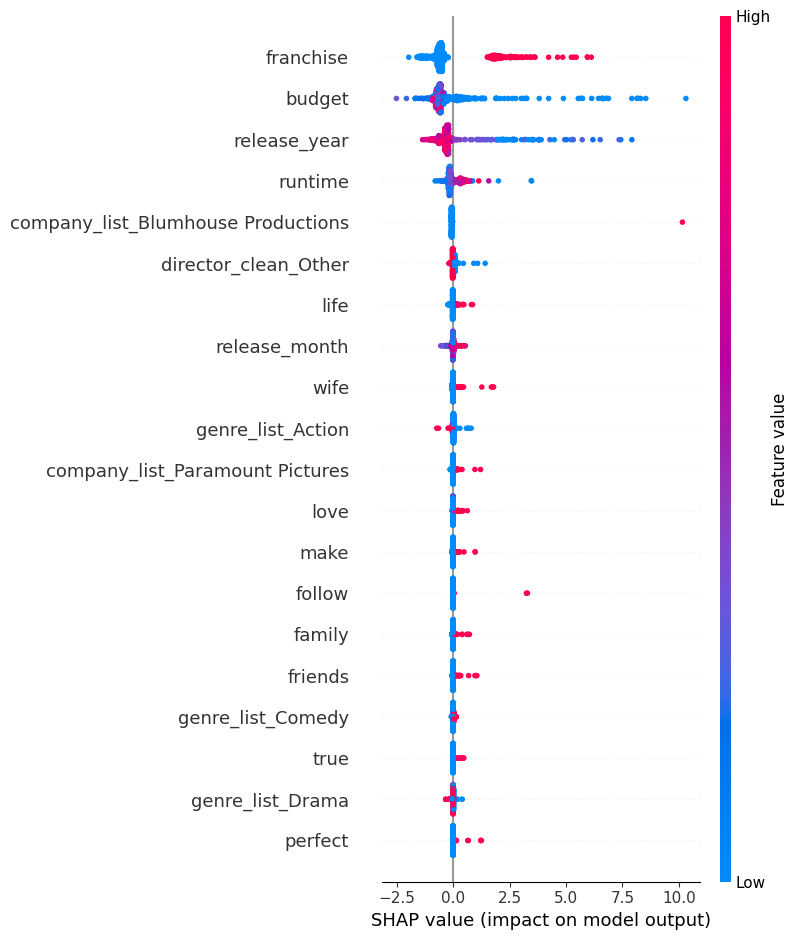

In [8]:
# ==========================================
# 7. SHAP Summary Plot
# ==========================================

shap.summary_plot(
    shap_values,
    X_sample
)

In [9]:
# ==========================================
# 8.1 Select One Movie
# ==========================================

movie_index = 0

movie_features = X_final.iloc[[movie_index]]

print("Movie Selected:")
print(model_df.loc[movie_index, ["budget",
                                 "runtime",
                                 "release_year",
                                 "roi"]])

Movie Selected:
budget          3.000000e+07
runtime         8.100000e+01
release_year    1.995000e+03
roi             1.145180e+01
Name: 0, dtype: float64


In [10]:
# ==========================================
# 8.2 Predict ROI
# ==========================================

predicted_roi = rf_model.predict(movie_features)[0]

print(f"Actual ROI    : {model_df.loc[movie_index, 'roi']:.4f}")
print(f"Predicted ROI : {predicted_roi:.4f}")

Actual ROI    : 11.4518
Predicted ROI : 3.8549


In [11]:
# ==========================================
# 8.3 SHAP Values for One Movie
# ==========================================

shap_value = explainer(movie_features)

print("SHAP values calculated successfully!")

SHAP values calculated successfully!


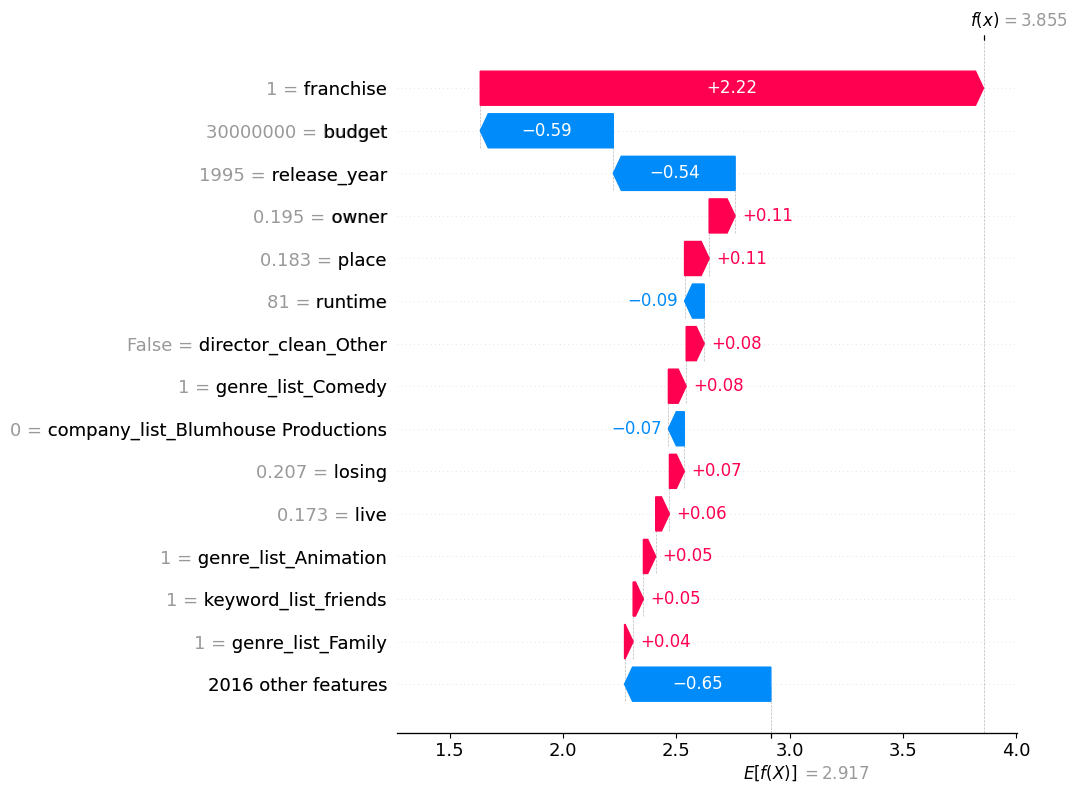

In [12]:
# ==========================================
# 8.4 Waterfall Plot
# ==========================================

shap.plots.waterfall(
    shap_value[0],
    max_display=15
)

In [13]:
# ==========================================
# 8.5 Force Plot
# ==========================================

shap.initjs()

shap.plots.force(
    shap_value[0]
)

In [14]:
# ==========================================
# 9.1 Select Different Types of Movies
# ==========================================

print(model_df["roi"].describe())

count    5321.000000
mean        2.925932
std         7.045987
min        -0.999999
25%        -0.217500
50%         1.025316
75%         3.143675
max        83.000000
Name: roi, dtype: float64


In [15]:
# ==========================================
# High ROI Movie
# ==========================================

high_movie = (
    model_df[
        (model_df["roi"] > 3) &
        (model_df["roi"] < 4)
    ]
    .index[0]
)

print("High ROI Movie Index:", high_movie)

model_df.loc[
    high_movie,
    ["budget", "runtime", "release_year", "roi"]
]

High ROI Movie Index: 1


budget          6.500000e+07
runtime         1.040000e+02
release_year    1.995000e+03
roi             3.043035e+00
Name: 1, dtype: float64

In [16]:
# ==========================================
# Average ROI Movie
# ==========================================

average_movie = (
    model_df[
        (model_df["roi"] > 0.95) &
        (model_df["roi"] < 1.10)
    ]
    .index[0]
)

print("Average ROI Movie Index:", average_movie)

model_df.loc[
    average_movie,
    ["budget", "runtime", "release_year", "roi"]
]

Average ROI Movie Index: 76


budget             8.0
runtime           98.0
release_year    1995.0
roi                1.0
Name: 76, dtype: float64

In [17]:
# ==========================================
# Low ROI Movie
# ==========================================

low_movie = (
    model_df[
        (model_df["roi"] > -0.30) &
        (model_df["roi"] < -0.20)
    ]
    .index[0]
)

print("Low ROI Movie Index:", low_movie)

model_df.loc[
    low_movie,
    ["budget", "runtime", "release_year", "roi"]
]

Low ROI Movie Index: 67


budget          2.500000e+07
runtime         9.700000e+01
release_year    1.995000e+03
roi            -2.369712e-01
Name: 67, dtype: float64

In [18]:
# ==========================================
# Explain One Movie
# ==========================================

def explain_movie(movie_index):

    movie_features = X_final.iloc[[movie_index]]

    predicted_roi = rf_model.predict(movie_features)[0]

    actual_roi = model_df.loc[movie_index, "roi"]

    print("=" * 60)
    print(f"Movie Index    : {movie_index}")
    print(f"Actual ROI     : {actual_roi:.4f}")
    print(f"Predicted ROI  : {predicted_roi:.4f}")

    shap_value = explainer(movie_features)

    shap.plots.waterfall(
        shap_value[0],
        max_display=15
    )

Movie Index    : 1
Actual ROI     : 3.0430
Predicted ROI  : 0.9689


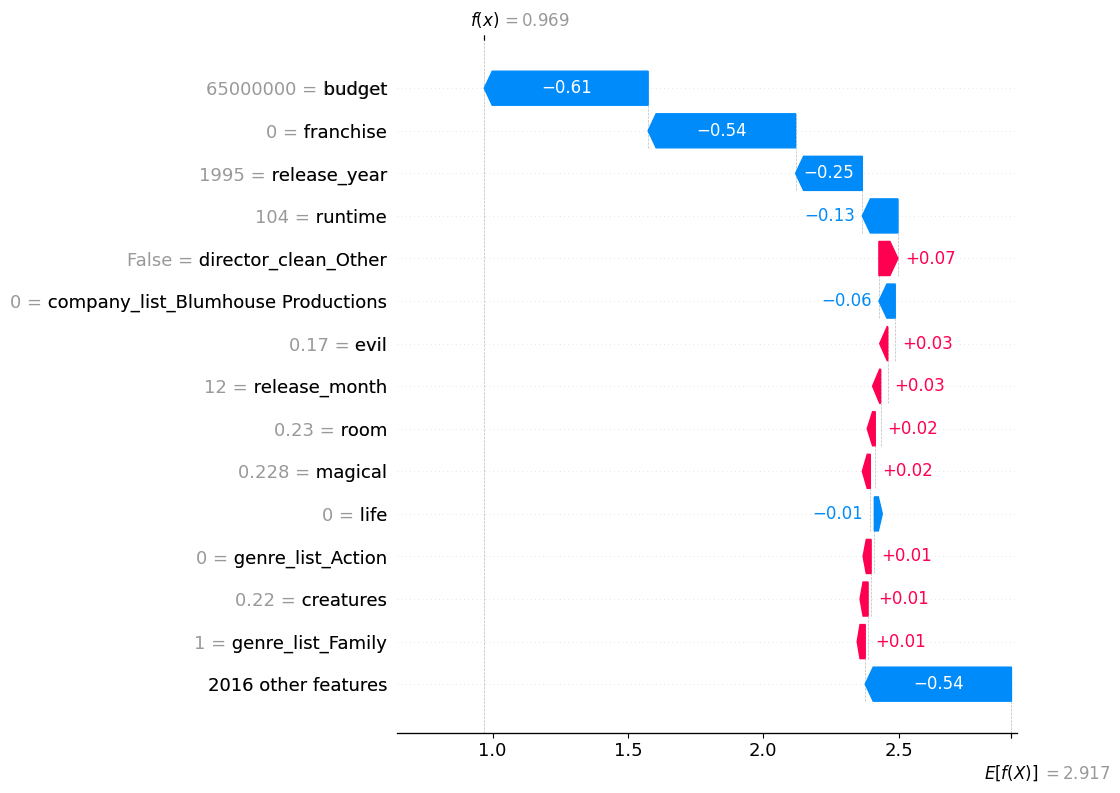

In [19]:
explain_movie(high_movie)

Movie Index    : 76
Actual ROI     : 1.0000
Predicted ROI  : 5.6633


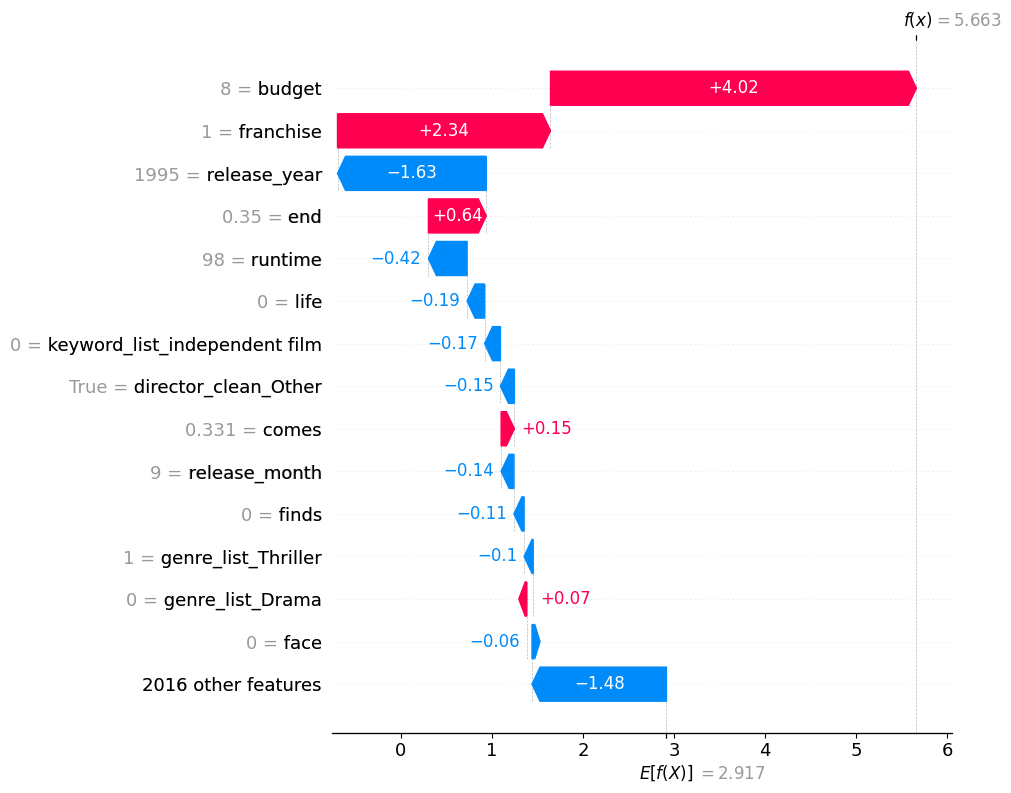

In [20]:
explain_movie(average_movie)

Movie Index    : 67
Actual ROI     : -0.2370
Predicted ROI  : 0.8739


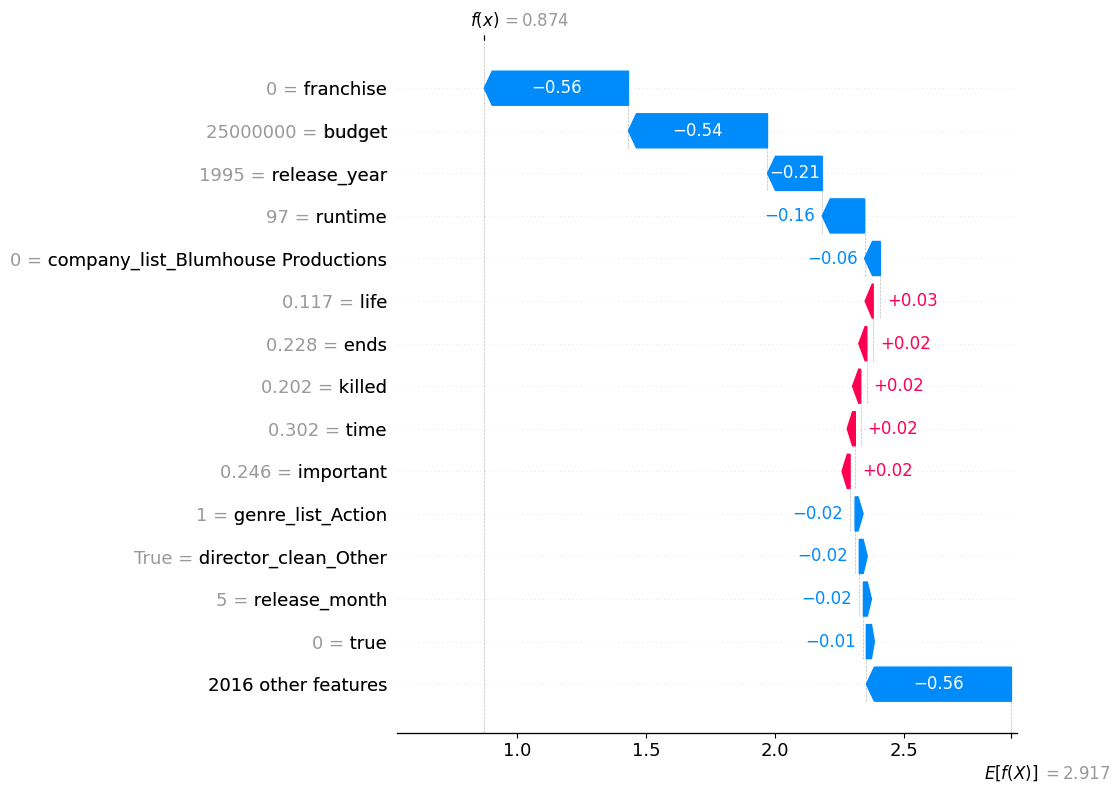

In [21]:
explain_movie(low_movie)

# Conclusion

This notebook applied SHAP (SHapley Additive exPlanations) to interpret the predictions of the Random Forest model.

Global explanations identified the most influential features affecting movie ROI, including franchise status, budget, release year, and runtime.

Local explanations demonstrated how individual features contributed to the predicted ROI for movies with high, average, and low returns.

The SHAP analysis improves the transparency of the proposed movie ROI prediction model and provides interpretable insights for the Decision Support System developed in Notebook 5.
